# Property Demand Forecasting Using LSTM

In this project, I am using past property sales data to understand demand patterns and predict sales for the next six months. The model uses the `Sales_Count` column and the previous 12 months of data to make a prediction.

### 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

### 2. Read the dataset

In [2]:
df = pd.read_csv("data/property_demand_forecasting_synthetic.csv")
df.head()

,Date,City,Property_Type,Sales_Count,Active_Listings,New_Listings,Average_Price_Lakh_INR,Home_Loan_Interest_Rate_Percent,Average_Days_On_Market
0,2006-01-01,Delhi,Apartment,73,910,127,26.95,8.54,57
1,2006-02-01,Delhi,Apartment,108,1011,123,28.63,8.40,61
2,2006-03-01,Delhi,Apartment,63,986,106,27.37,8.65,66
3,2006-04-01,Delhi,Apartment,91,1022,121,28.45,8.70,64
4,2006-05-01,Delhi,Apartment,115,983,117,33.49,8.38,60


In [3]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (240, 9)

Columns:
['Date', 'City', 'Property_Type', 'Sales_Count', 'Active_Listings', 'New_Listings', 'Average_Price_Lakh_INR', 'Home_Loan_Interest_Rate_Percent', 'Average_Days_On_Market']


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 9 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Date                             240 non-null    str    
 1   City                             240 non-null    str    
 2   Property_Type                    240 non-null    str    
 3   Sales_Count                      240 non-null    int64  
 4   Active_Listings                  240 non-null    int64  
 5   New_Listings                     240 non-null    int64  
 6   Average_Price_Lakh_INR           240 non-null    float64
 7   Home_Loan_Interest_Rate_Percent  240 non-null    float64
 8   Average_Days_On_Market           240 non-null    int64  
dtypes: float64(2), int64(4), str(3)
memory usage: 22.6 KB


In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
Date                               0
City                               0
Property_Type                      0
Sales_Count                        0
Active_Listings                    0
New_Listings                       0
Average_Price_Lakh_INR             0
Home_Loan_Interest_Rate_Percent    0
Average_Days_On_Market             0
dtype: int64

Duplicate rows: 0


In [6]:
df.describe()

,Sales_Count,Active_Listings,New_Listings,Average_Price_Lakh_INR,Home_Loan_Interest_Rate_Percent,Average_Days_On_Market
count,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,194.279167,1110.191667,133.462500,85.392542,7.147583,57.112500
std,62.178858,144.181011,21.142638,33.027735,0.891641,6.307319
min,48.000000,798.000000,87.000000,26.950000,6.000000,36.000000
25%,145.750000,996.500000,118.000000,56.262500,6.400000,52.750000
50%,193.000000,1104.500000,132.000000,85.050000,7.140000,57.000000
75%,238.250000,1211.500000,147.000000,114.232500,7.705000,61.000000
max,319.000000,1438.000000,207.000000,145.580000,8.930000,75.000000


### 3. Clean the data

In [7]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Sales_Count"] = pd.to_numeric(df["Sales_Count"], errors="coerce")

df = df.dropna(subset=["Date", "Sales_Count"])
df = df.sort_values("Date").reset_index(drop=True)

# If the file has more than one record for a date, combine them into one total.
df = df.groupby("Date", as_index=False)["Sales_Count"].sum()
df = df.sort_values("Date").reset_index(drop=True)

print("Total rows after cleaning:", len(df))
print("Date range:", df["Date"].min(), "to", df["Date"].max())
df.head()

Total rows after cleaning: 240
Date range: 2006-01-01 00:00:00 to 2025-12-01 00:00:00


,Date,Sales_Count
0,2006-01-01,73
1,2006-02-01,108
2,2006-03-01,63
3,2006-04-01,91
4,2006-05-01,115


### 4. Visualize property demand

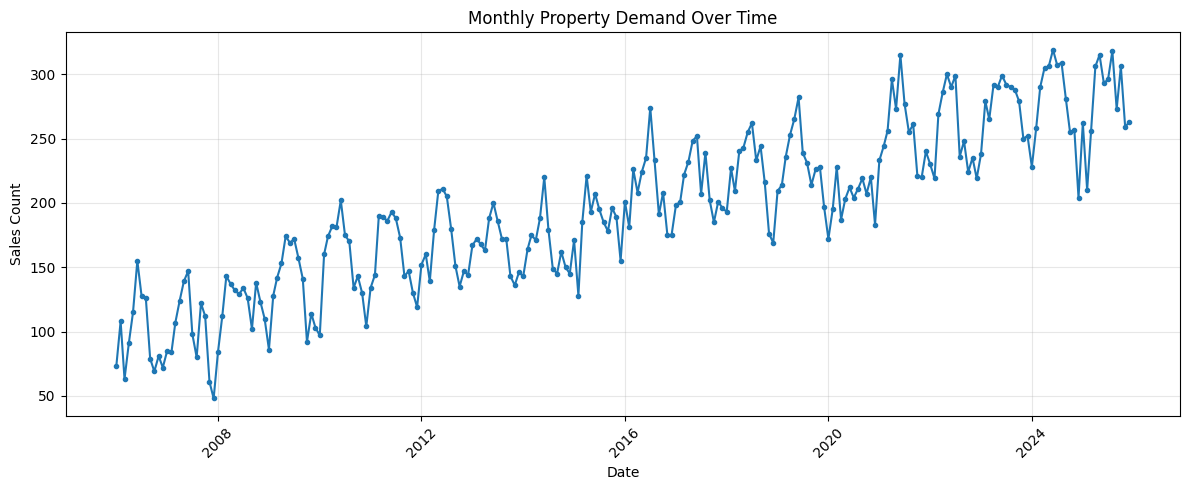

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Sales_Count"], marker="o", markersize=3)
plt.title("Monthly Property Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Sales Count")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 5. Split the data

In [9]:
# Keep the data in date order. The latest months are used for testing.
values = df["Sales_Count"].to_numpy(dtype=float).reshape(-1, 1)
n = len(values)

LOOKBACK = 12
if n <= LOOKBACK + 5:
    raise ValueError("There are not enough rows to train and test this model.")

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_raw = values[:train_end]
val_raw = values[train_end:val_end]
test_raw = values[val_end:]

print("Training rows:", len(train_raw))
print("Validation rows:", len(val_raw))
print("Testing rows:", len(test_raw))

Training rows: 168
Validation rows: 36
Testing rows: 36


### 6. Scale the values and prepare sequences

In [10]:
# Fit the scaler only on training data.
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_raw)
val_scaled = scaler.transform(val_raw)
test_scaled = scaler.transform(test_raw)

def create_sequences(data, lookback=LOOKBACK):
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i - lookback:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled)

# Use earlier months as context when preparing validation and test sequences.
val_context = np.vstack([train_scaled[-LOOKBACK:], val_scaled])
X_val, y_val = create_sequences(val_context)

test_context = np.vstack([val_context[-LOOKBACK:], test_scaled])
X_test, y_test = create_sequences(test_context)

# LSTM expects input in the form: samples, time steps, features.
X_train = X_train.reshape((X_train.shape[0], LOOKBACK, 1))
X_val = X_val.reshape((X_val.shape[0], LOOKBACK, 1))
X_test = X_test.reshape((X_test.shape[0], LOOKBACK, 1))

print("Training sequence shape:", X_train.shape)
print("Validation sequence shape:", X_val.shape)
print("Testing sequence shape:", X_test.shape)

Training sequence shape: (156, 12, 1)
Validation sequence shape: (36, 12, 1)
Testing sequence shape: (36, 12, 1)


### 7. Build the LSTM model

In [11]:
model = Sequential([
    LSTM(64, input_shape=(LOOKBACK, 1)),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")
model.summary()

C:\Users\Roshan\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

### 8. Train the model

In [12]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step - loss: 0.0728 - val_loss: 0.0199
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0326 - val_loss: 0.0211
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0221 - val_loss: 0.0399
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0166 - val_loss: 0.0189
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0205 - val_loss: 0.0211
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0179 - val_loss: 0.0248
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0154 - val_loss: 0.0193
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0189 - val_loss: 0.0231
Epoch 9/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0174 - val_loss: 0.0213
Epoch 10/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0168 - val_loss: 0.0205
Epoch 11/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0177 - val_loss: 0.0204
Epoch 12/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step

### 9. Check the training loss

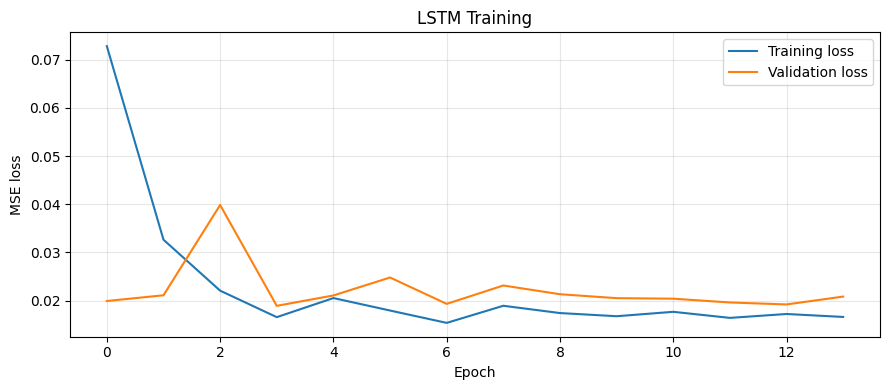

In [13]:
plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("LSTM Training")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 10. Evaluate the model

In [14]:
pred_scaled = model.predict(X_test, verbose=0)

y_actual = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()
y_pred = scaler.inverse_transform(pred_scaled).ravel()

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE: 28.88
RMSE: 33.92


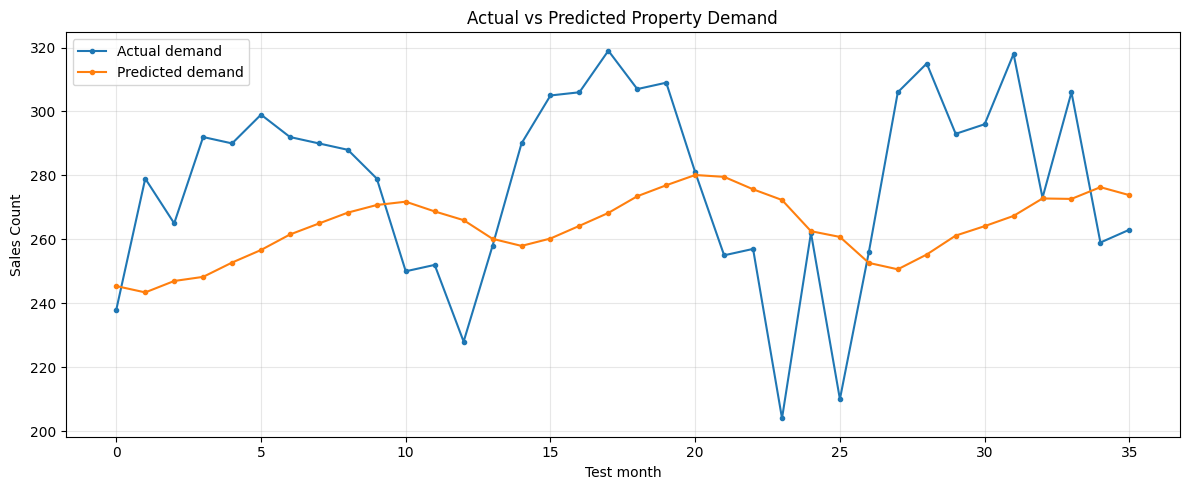

In [15]:
plt.figure(figsize=(12, 5))
plt.plot(y_actual, label="Actual demand", marker="o", markersize=3)
plt.plot(y_pred, label="Predicted demand", marker="o", markersize=3)
plt.title("Actual vs Predicted Property Demand")
plt.xlabel("Test month")
plt.ylabel("Sales Count")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 11. Forecast the next six months

In [16]:
# Start with the latest 12 months, scaled with the same scaler used for training.
last_sequence = scaler.transform(values[-LOOKBACK:]).flatten()
current_sequence = last_sequence.copy()
future_predictions = []

for month in range(6):
    input_data = current_sequence.reshape(1, LOOKBACK, 1).astype("float32")
    next_scaled = float(model.predict(input_data, verbose=0)[0, 0])

    next_value = scaler.inverse_transform([[next_scaled]])[0, 0]
    future_predictions.append(max(0, next_value))

    # Add this prediction to the sequence before forecasting the next month.
    current_sequence = np.append(current_sequence[1:], next_scaled)

future_dates = pd.date_range(
    start=df["Date"].max() + pd.offsets.MonthBegin(1),
    periods=6,
    freq="MS"
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Sales_Count": np.round(future_predictions, 2)
})

forecast_df

,Date,Predicted_Sales_Count
0,2026-01-01,272.16
1,2026-02-01,270.81
2,2026-03-01,269.96
3,2026-04-01,268.49
4,2026-05-01,266.50
5,2026-06-01,264.53


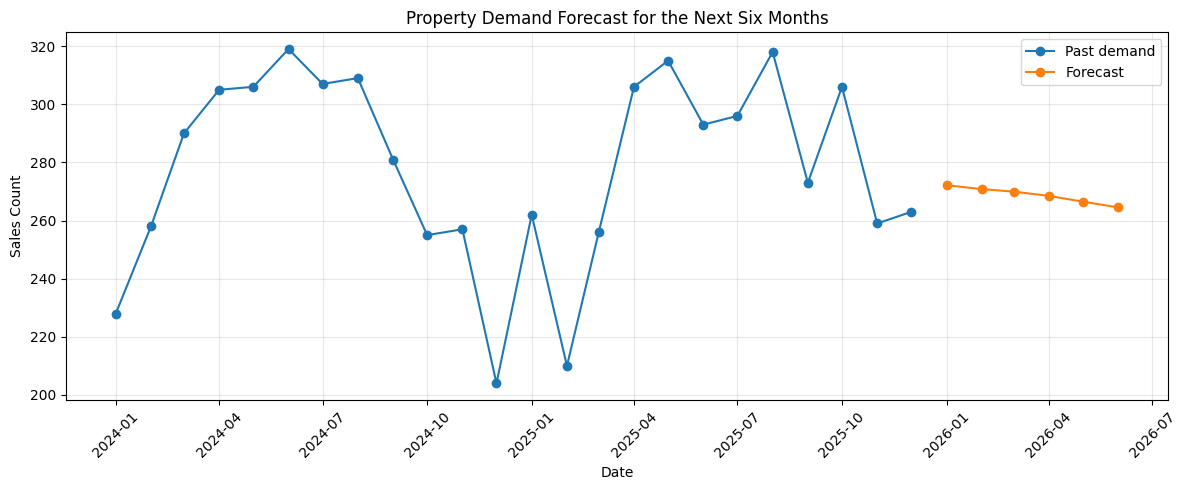

In [17]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"].tail(24), df["Sales_Count"].tail(24),
         label="Past demand", marker="o")
plt.plot(forecast_df["Date"], forecast_df["Predicted_Sales_Count"],
         label="Forecast", marker="o")
plt.title("Property Demand Forecast for the Next Six Months")
plt.xlabel("Date")
plt.ylabel("Sales Count")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 12. Save the forecast and model

In [ ]:
import os

os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)

forecast_df.to_csv("outputs/future_6_month_forecast.csv", index=False)
model.save("property_demand_lstm.keras")

print("Forecast saved to outputs/future_6_month_forecast.csv")
print("Model saved to property_demand_lstm.keras")

### Conclusion

In this project, I trained an LSTM model on historical `Sales_Count` values and used it to forecast property demand for the next six months. MAE and RMSE show how far the model's predictions are from the actual test values.

The forecast is based only on past sales counts. The dataset file name suggests it may be synthetic, so the results should be treated as a project demonstration rather than a real-estate market prediction. The notebook should be run with the CSV file to generate the final metrics and forecast values.